In [1]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from protgen.data import ProteinDataset
from torch.utils.data import DataLoader
from protgen.data import AA, FAMILIES, IGNORE_INDEX, special_tokens
import random
from torch.nn.utils.rnn import pad_sequence

import matplotlib.pyplot as plt

In [2]:
train_data = ProteinDataset(path_to_data="../data/train.csv")
val_data = ProteinDataset(path_to_data="../data/val.csv")
test_data = ProteinDataset(path_to_data="../data/test.csv")

print(f"Data class: {train_data}")

# Get tensors
X_train = train_data.tokens
y_train_labels = train_data.labels          # classification task
y_train_shifted = train_data.tokens_shifted # generative task

print(f"# Train data: \n Tokens shape: {X_train.shape}\n Labels (shape): {y_train_labels.shape} \n Shifted shape: {y_train_shifted.shape}")


# Inddexing
x, x_shifted, y, length = train_data[0]
print(f"# Sample 0: \nTokens: \n {x}\n Shifted: \n {x_shifted}\n Label: {y}\n Length: {length}")

# DataLoader
train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
val_loader = DataLoader(val_data, batch_size=32, shuffle=True)

Data class: ProteinDataset(num_samples=16020, vocab_size=23, num_classes=3, max_length=129)
# Train data: 
 Tokens shape: torch.Size([16020, 129])
 Labels (shape): torch.Size([16020]) 
 Shifted shape: torch.Size([16020, 129])
# Sample 0: 
Tokens: 
 tensor([ 1, 13, 10, 11, 11, 16,  7, 14, 10, 10, 11, 14, 19,  8,  7,  3, 17, 15,
         3, 19, 12, 12, 20, 11, 12, 18, 16, 17,  7, 19, 18,  5, 10, 18, 12,  6,
        22, 16,  8, 11, 19, 10, 14, 12, 11,  9, 18,  3, 11, 18, 10, 13,  5, 10,
        13, 18, 12, 18, 10, 17, 15,  8, 19, 11,  7, 22, 10, 11,  3,  6,  8, 10,
         5,  6, 20, 16,  3, 10, 16, 12, 10, 16,  5, 22, 12, 22, 11,  6, 11, 12,
        10, 14, 22,  2,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0])
 Shifted: 
 tensor([13, 10, 11, 11, 16,  7, 14, 10, 10, 11, 14, 19,  8,  7,  3, 17, 15,  3,
        19, 12, 12, 20, 11, 12, 18, 16, 17,  7, 19, 18,  5, 10, 18, 12,  6, 22

In [3]:
print(f"vocab ({train_data.vocab_size} tokens): {train_data.vocab}")
print(f"families: {train_data.fam_to_idx}")
print(f"padding is ignored in the loss with ignore_index={IGNORE_INDEX}")

sequence = train_data.df["sequence"][0]
tokens = train_data.encode(sequence)
print()
print(f"encode / decode round-trips: {train_data.decode(tokens) == sequence}")
print(f"and from the shifted target too:  {train_data.decode(x_shifted) == sequence}")

vocab (23 tokens): {'<PAD>': 0, '<BOS>': 1, '<EOS>': 2, 'A': 3, 'C': 4, 'D': 5, 'E': 6, 'F': 7, 'G': 8, 'H': 9, 'I': 10, 'K': 11, 'L': 12, 'M': 13, 'N': 14, 'P': 15, 'Q': 16, 'R': 17, 'S': 18, 'T': 19, 'V': 20, 'W': 21, 'Y': 22}
families: {'AcyP': 0, 'HPr': 1, 'HU': 2}
padding is ignored in the loss with ignore_index=-1

encode / decode round-trips: True
and from the shifted target too:  True


In [4]:
x, x_shifted, y, length = next(iter(train_loader))
print(f"batch: x {tuple(x.shape)} {x.dtype}, x_shifted {tuple(x_shifted.shape)}, y {tuple(y.shape)}")

# Generative: one distribution over the vocabulary per position.
logits_gen = torch.randn(x.shape[0], train_data.vocab_size, train_data.max_length)
print(f"generative loss:     {F.cross_entropy(logits_gen, x_shifted, ignore_index=IGNORE_INDEX):.4f}")

# Classification: one distribution over the three families per sequence.
logits_fam = torch.randn(x.shape[0], len(FAMILIES))
print(f"classification loss: {F.cross_entropy(logits_fam, y):.4f}")

batch: x (32, 129) torch.int64, x_shifted (32, 129), y (32,)
generative loss:     3.5983
classification loss: 1.1040


In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [6]:
class NoisyPredictor(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_layers, num_classes, dropout=0.2):
        super().__init__()

        self.embedding = nn.Embedding(vocab_size, embed_dim)

        self.rnn = nn.LSTM(embed_dim, hidden_dim, num_layers, 
                           batch_first=True, 
                           dropout=dropout if num_layers > 1 else 0
        )
        self.fc = nn.Linear(hidden_dim, num_classes)

    def forward(self, x: torch.Tensor, length):
        x = self.embedding(x)
        output, (h_n, c_n) = self.rnn(x) # For LSTM

        idx = torch.arange(x.size(0), device=x.device)
        last_hidden = output[idx, length - 1]
        result = self.fc(last_hidden)

        return result

In [7]:
# Param setting
# Dataset parameters
vocab_size = train_data.vocab_size
num_classes = len(train_data.fam_to_idx)
pad_id = 0
bos_id = 1
eos_id = 2

# Model parameters
num_epochs = 10
# context_size = 3 # 16, 32, 64, 128
embed_dim = 32
hidden_dim = 128
max_length = 128
num_layers = 2
dropout = 0.2

learning_rate = 1e-4

In [8]:
predictor = NoisyPredictor(
    vocab_size = vocab_size,
    embed_dim = embed_dim,
    hidden_dim = hidden_dim,
    num_layers = num_layers,
    num_classes = num_classes,
    dropout = dropout
).to(device)

optimizer = torch.optim.Adam(predictor.parameters(), lr=learning_rate)

In [9]:
def make_noisy(x, lengths):
    noisy_sequences = []

    for seq, length in zip(x, lengths):
        prefix_length = random.randint(1, int(length))

        # BOS + randomly selected amino acids
        truncated = seq[:prefix_length + 1]

        noisy_sequences.append(truncated)

    new_lengths = torch.tensor(
        [len(seq) for seq in noisy_sequences],
        device=x.device
    )

    x_noisy = pad_sequence(
        noisy_sequences,
        batch_first=True,
        padding_value=0
    )

    return x_noisy, new_lengths

In [10]:
# NoisyPredictor training
def train(predictor, train_loader, optimizer, device="cpu"):
    predictor.train()

    total_loss = 0
    total_correct = 0
    total_tokens = 0

    for x, x_shifted, y, length in train_loader:
        x_noisy, new_length = make_noisy(x, length)

        x_noisy = x_noisy.to(device)
        x_shifted = x_shifted.to(device)
        new_length = new_length.to(device)
        y = y.to(device)

        # Forward
        outputs = predictor(x_noisy, new_length)

        loss = F.cross_entropy(
            outputs,
            y
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # calculate loss and accuracy
        total_loss += loss.item() * y.size(0)

        predictions = outputs.argmax(dim=-1)
        total_correct += ((predictions == y)).sum().item()

        total_tokens += y.size(0)

    avg_loss = total_loss / total_tokens
    avg_accuracy = total_correct / total_tokens

    return avg_loss, avg_accuracy

In [11]:
# NoisyPredictor validation
@torch.no_grad()
def validation(predictor, val_data, optimizer, device="cpu"):
    predictor.eval()
    
    total_loss = 0
    total_correct = 0
    total_tokens = 0

    for x, x_shifted, y, length in val_data:
        x_noisy, new_length = make_noisy(x, length)

        x_noisy = x_noisy.to(device)
        x_shifted = x_shifted.to(device)
        new_length = new_length.to(device)
        y = y.to(device)

        # Forward
        outputs = predictor(x_noisy, new_length)

        loss = F.cross_entropy(
            outputs,
            y
        )

        # calculate loss and accuracy
        total_loss += loss.item() * y.size(0)

        predictions = outputs.argmax(dim=-1)
        total_correct += ((predictions == y)).sum().item()

        total_tokens += y.size(0)

    avg_loss = total_loss / total_tokens
    avg_accuracy = total_correct / total_tokens

    return avg_loss, avg_accuracy

In [12]:
best_val_loss = float("inf")

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}
rows = []

patience = 10
counter = 0

for epoch in range(num_epochs):
    train_loss, train_acc = train(predictor, train_loader, optimizer, device)
    val_loss, val_acc = validation(predictor, val_loader, optimizer, device)
    
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    # find the best model
    if val_loss < best_val_loss:
        counter = 0

        best_val_loss = val_loss
        best_val_acc = val_acc
        best_epoch = epoch
        torch.save(predictor, "best_classifier_model.pt")
    else:
        counter += 1

    if counter >= patience:
        print("Early stopping")
        break
    
    print(f"Epoch {epoch+1}/{num_epochs}")
    print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")

print(f"The best model was saved at epoch {best_epoch+1} with val loss {best_val_loss:.4f} and val acc {best_val_acc:.4f}")

Epoch 1/10
Train Loss: 0.7763, Train Acc: 0.6160
Val Loss: 0.5364, Val Acc: 0.7481
Epoch 2/10
Train Loss: 0.4424, Train Acc: 0.8147
Val Loss: 0.3618, Val Acc: 0.8676
Epoch 3/10
Train Loss: 0.2996, Train Acc: 0.8821
Val Loss: 0.2488, Val Acc: 0.9050
Epoch 4/10
Train Loss: 0.2693, Train Acc: 0.8895
Val Loss: 0.2418, Val Acc: 0.9145
Epoch 5/10
Train Loss: 0.2809, Train Acc: 0.8855
Val Loss: 0.2392, Val Acc: 0.9075
Epoch 6/10
Train Loss: 0.2334, Train Acc: 0.9035
Val Loss: 0.2221, Val Acc: 0.9185
Epoch 7/10
Train Loss: 0.2384, Train Acc: 0.9069
Val Loss: 0.2298, Val Acc: 0.9130
Epoch 8/10
Train Loss: 0.2112, Train Acc: 0.9127
Val Loss: 0.2084, Val Acc: 0.9205
Epoch 9/10
Train Loss: 0.2016, Train Acc: 0.9197
Val Loss: 0.1997, Val Acc: 0.9315
Epoch 10/10
Train Loss: 0.1995, Train Acc: 0.9147
Val Loss: 0.1845, Val Acc: 0.9435
The best model was saved at epoch 10 with val loss 0.1845 and val acc 0.9435


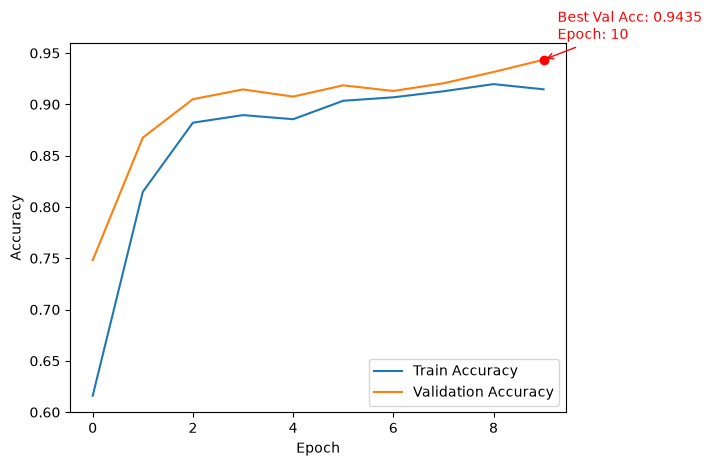

The parameter:
Epoch Number: 10
Embedding Dimension: 32
Hidden Dimension: 128
LSTM Layers: 2
dropout: 0.2
Learning Rate: 0.0001


In [13]:
plt.plot(history["train_acc"], label="Train Accuracy")
plt.plot(history["val_acc"], label="Validation Accuracy")

# Mark best validation loss
plt.scatter(best_epoch, best_val_acc, color="red", zorder=5)
plt.annotate(
    f"Best Val Acc: {best_val_acc:.4f}\nEpoch: {best_epoch + 1}",
    xy=(best_epoch, best_val_acc),
    xytext=(10, 15),
    textcoords="offset points",
    color="red",
    arrowprops=dict(arrowstyle="->", color="red")
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

print(f"The parameter:")
print(f"Epoch Number: {num_epochs}")
print(f"Embedding Dimension: {embed_dim}")
print(f"Hidden Dimension: {hidden_dim}")
print(f"LSTM Layers: {num_layers}")
print(f"dropout: {dropout}")
print(f"Learning Rate: {learning_rate}")